# Tasks 2–4: SHAP Explanations of a Random Forest

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 1

**Objective:** explain the provided random forest stroke classifier with SHAP (Lundberg & Lee, 2017): build and verify the explainer (Task 2), explain one patient (Task 3) and the whole model (Task 4).

**Approach:** the provided pipeline (`scripts/03_shap.py`, deepfindr, 2021) is the *baseline*. An *improved* pipeline fixes the BMI artefact found in the [EDA](01_eda.ipynb) and tunes the decision threshold.

**Outcome:** `stroke = 1` is a *recorded history* of stroke; model outputs are classification scores, not future stroke risks.

**Contents**
1. [Setup](#sec-setup)
2. [Pipelines](#sec-pipelines)
3. [Model performance](#sec-performance)
4. [Task 2: SHAP explainer](#sec-explainer)
5. [Task 3: Local explanation](#sec-local)
6. [Task 4: Global explanation](#sec-global)
7. [Feature effects](#sec-dependence)
8. [Robustness checks](#sec-robustness)
9. [Supplementary cases](#sec-supplementary)
10. [Key takeaways](#sec-takeaways)
11. [References](#sec-references)

<a id="sec-setup"></a>

## 1. Setup

Shared helpers (data loading, models, explainers, figure theme) are in the `stroke_shap` package under `src/`. Package versions are recorded in [notebook 01, Section 0](01_eda.ipynb#sec-provided).

In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from matplotlib.text import Text
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import ConfusionMatrixDisplay, brier_score_loss, roc_auc_score, roc_curve

from stroke_shap import SEED
from stroke_shap.data import DATA_PATH, axis_label, display_label, load_split
from stroke_shap.explain import additivity_residual, importance_by_variable, tree_shap
from stroke_shap.models import (
    evaluate,
    make_random_forest,
    out_of_fold_scores,
    select_main_case,
    youden_threshold,
)
from stroke_shap.plotting import COLORS, FIGURE_WIDTH, force_plot, label_panels, save_figure, set_theme

set_theme()
BACKGROUND_SIZE = 100

<a id="sec-pipelines"></a>

## 2. Pipelines

Both pipelines share the split, oversampling and model, so they differ only in BMI handling and threshold.

| Step | Baseline (provided) | Improved |
|---|---|---|
| Predictors | 10 variables, one-hot encoded; `id` used only as the index | same, plus `bmi_missing` |
| Missing BMI (201 rows) | filled with 0 | training median (refitted per cross-validation fold), plus a `bmi_missing` flag |
| Split | 80/20, `random_state=2021` | same |
| Class imbalance | `RandomOverSampler`, training data only | same |
| Model | `RandomForestClassifier`, 100 trees, defaults | same |
| Threshold | 0.5 | tuned on the training set ([Section 3.1](#sec-performance)) |

**Why:**
- **BMI = 0** is impossible, and missing BMI has 4.7× the stroke share (19.9% vs 4.3%, [EDA, Section 4.1](01_eda.ipynb#sec-quality)), so the baseline can learn "BMI = 0 → stroke". The flag makes this signal explicit.
- **Seeds:** the provided code seeds neither the oversampler nor the forest; both use `SEED = 2021` here.
- **Stratification** is not needed: the split already puts 4.9% strokes in the test set, the same as the full data.

In [2]:
baseline, improved = load_split("baseline"), load_split("improved")
assert baseline.X_test.index.equals(improved.X_test.index), "both pipelines must share the test set"
X_train, X_test, y_train, y_test = improved
labels = X_test.columns.map(display_label)

rf_baseline = make_random_forest().fit(baseline.X_train, baseline.y_train)
rf = make_random_forest().fit(X_train, y_train)

pd.DataFrame(
    {"Patients": [len(X_train), len(X_test)], "Strokes": [y_train.sum(), y_test.sum()]},
    index=["Train", "Test"],
).assign(**{"Stroke Share": lambda d: (d["Strokes"] / d["Patients"]).round(3)})

,Patients,Strokes,Stroke Share
Train,4088,199,0.049
Test,1022,50,0.049


<a id="sec-performance"></a>

## 3. Model performance

The classes are imbalanced about 20 : 1 (4.9% strokes). Predicting "no stroke" for every test patient scores 95.1% accuracy (972 of 1,022), more than the baseline model (94.3%). Recall, precision, balanced accuracy, ROC AUC and average precision are reported instead.

### 3.1 Decision threshold

**Question:** at which score should a patient be flagged?

**Method:**
- **Why not 0.5:** few unseen patients score above it. `RandomOverSampler` only copies the 199 training strokes, and fully grown trees memorise these copies. A new stroke patient matches none of them, so it usually lands in leaves dominated by the varied non-stroke patients, and most trees vote "no stroke".
- 5-fold stratified cross-validation on the training set refits the pipeline on four folds and scores the fifth, giving every training patient one out-of-fold score.
- One ROC curve over all 4,088 pooled scores (not an average of five fold curves); the threshold maximises Youden's J (Youden, 1950):

$$J = \text{recall} + \text{specificity} - 1$$

- The fold models are discarded and the test set is not used.

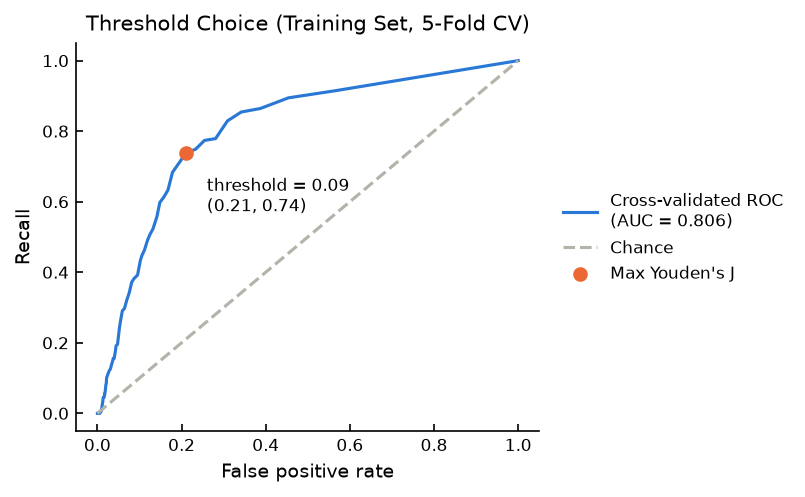

In [3]:
oof = out_of_fold_scores(make_random_forest(), X_train, y_train)
threshold = youden_threshold(y_train, oof)
fpr, tpr, cutoffs = roc_curve(y_train, oof)
best = np.flatnonzero(cutoffs == threshold)[0]

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 3.2))
ax.plot(fpr, tpr, label=f"Cross-validated ROC\n(AUC = {roc_auc_score(y_train, oof):.3f})")
ax.plot([0, 1], [0, 1], color=COLORS["grey"], ls="--", label="Chance")
ax.scatter(
    fpr[best],
    tpr[best],
    color=COLORS["orange"],
    zorder=3,
    label="Max Youden's J",
)
ax.annotate(
    f"threshold = {threshold:.2f}\n({fpr[best]:.2f}, {tpr[best]:.2f})",
    (fpr[best], tpr[best]),
    xytext=(10, -28),
    textcoords="offset points",
    fontsize=8,
)
ax.set(xlabel="False positive rate", ylabel="Recall", title="Threshold Choice (Training Set, 5-Fold CV)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
save_figure(fig, "shap_threshold")
plt.show()

### 3.2 Test-set comparison

**Result:**
- **Default threshold (0.5):** both models catch only 4–5 of 50 strokes, despite 94% accuracy.
- **BMI fix:** ROC AUC 0.73 → 0.75; average precision 0.12 → 0.14 (0.05 for a random ranking).
- **Tuned threshold (0.09):** 29 of 50 strokes caught; balanced accuracy 0.54 → 0.67. The cost is 225 false alarms: about 1 in 9 alerts is a stroke (precision 0.11).

**Implication:** the model ranks better than chance but is a weak screening tool, still missing 21 of 50 strokes. The tuned improved random forest is explained from here on; SHAP values do not depend on the threshold.

In [4]:
proba_baseline = pd.Series(rf_baseline.predict_proba(baseline.X_test)[:, 1], index=X_test.index)
proba = pd.Series(rf.predict_proba(X_test)[:, 1], index=X_test.index)
runs = {
    "Baseline Random Forest, Threshold 0.5": (proba_baseline, 0.5),
    "Improved Random Forest, Threshold 0.5": (proba, 0.5),
    f"Improved Random Forest, Threshold {threshold:.2f}": (proba, threshold),
}

results = pd.DataFrame.from_dict(
    {name: evaluate(y_test, p, t) for name, (p, t) in runs.items()}, orient="index"
)
results.round(2).astype(object).T  # object dtype keeps the counts as integers after transposing

,"Baseline Random Forest, Threshold 0.5","Improved Random Forest, Threshold 0.5","Improved Random Forest, Threshold 0.09"
Strokes Caught (TP),4,5,29
Strokes Missed (FN),46,45,21
False Alarms (FP),12,14,225
Correctly Cleared (TN),960,958,747
Recall,0.08,0.1,0.58
Precision,0.25,0.26,0.11
F1,0.12,0.14,0.19
Balanced Accuracy,0.53,0.54,0.67
Accuracy,0.94,0.94,0.76
ROC AUC,0.73,0.75,0.75


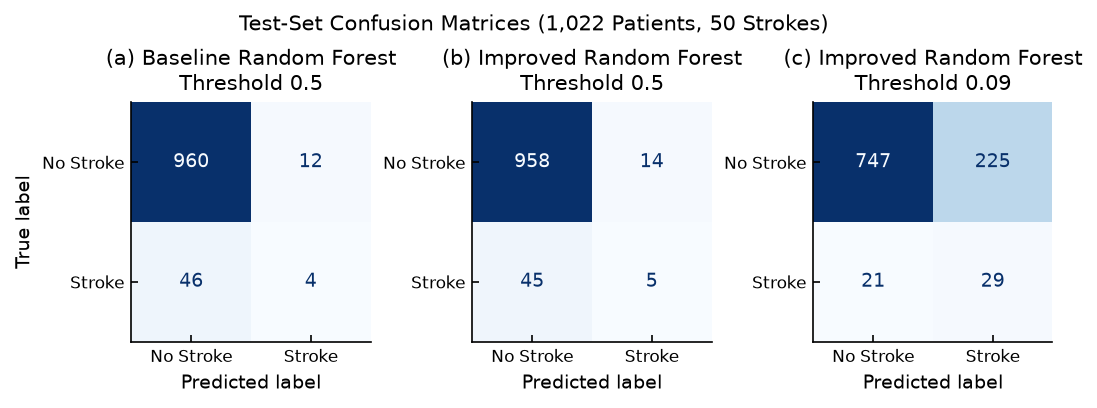

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, 2.6))
for ax, (name, (p, t)) in zip(axes, runs.items(), strict=True):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p >= t, display_labels=["No Stroke", "Stroke"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name.replace(", ", "\n"))
for ax in axes[1:]:
    ax.set_ylabel("")
label_panels(axes)
fig.suptitle("Test-Set Confusion Matrices (1,022 Patients, 50 Strokes)")
save_figure(fig, "shap_confusion")
plt.show()

### 3.3 Calibration

**Question:** can the score be read as the chance of a recorded stroke?

**Result:** no. The highest-scoring patients lie well below the diagonal: the model overstates their probability, as expected after oversampling to 50% strokes. Scores are used only to rank patients against the threshold.

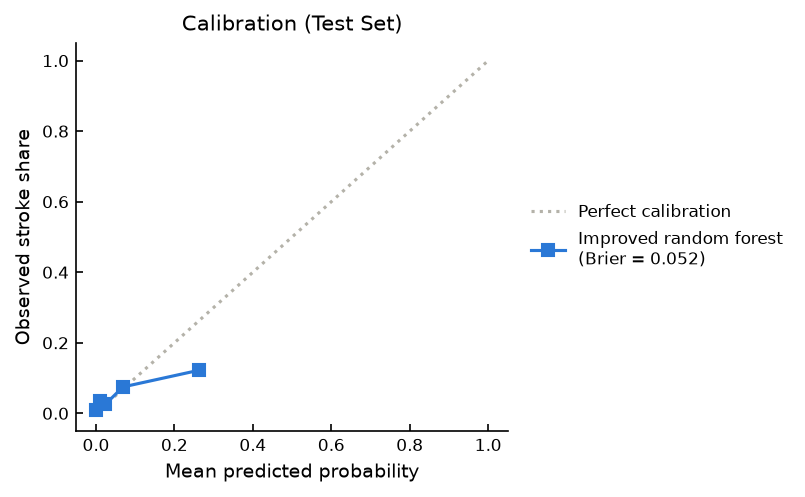

In [6]:
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 3.2))
CalibrationDisplay.from_predictions(
    y_test,
    proba,
    n_bins=5,
    strategy="quantile",
    ax=ax,
    name=f"Improved random forest\n(Brier = {brier_score_loss(y_test, proba):.3f})",
)
ax.get_lines()[0].set(color=COLORS["grey"], label="Perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed stroke share", title="Calibration (Test Set)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
save_figure(fig, "shap_calibration")
plt.show()

<a id="sec-explainer"></a>

## 4. Task 2: SHAP explainer

### 4.1 Specification

- **Explainer:** `shap.TreeExplainer`, exact SHAP values for tree ensembles without sampling (Lundberg et al., 2020).
- **Output:** predicted probability of stroke (class 1).
- **Background:** *interventional*, 100 training patients sampled before oversampling. The base value is the model's average output over these real patients. The provided default (*tree path-dependent*) is compared in [Section 8.1](#sec-robustness).
- **Explained:** all 1,022 test patients.

Each patient's SHAP values add up to the gap between their prediction and the base value:

$$f(x) = \phi_0 + \sum_{j=1}^{M} \phi_j$$

$\phi_j > 0$ pushes towards stroke, $\phi_j < 0$ away. SHAP describes how *this model* uses a feature, not whether the feature causes stroke.

In [7]:
background = X_train.sample(BACKGROUND_SIZE, random_state=SEED)
shap_values, base_value = tree_shap(rf, X_test, background)
shap_values_baseline, base_value_baseline = tree_shap(
    rf_baseline, baseline.X_test, baseline.X_train.loc[background.index]
)

pd.Series(
    {
        "shap": version("shap"),
        "scikit-learn": version("scikit-learn"),
        "Base value, improved": f"{base_value:.3f}",
        "Base value, baseline": f"{base_value_baseline:.3f}",
    }
).to_frame("Value")

100%|===================| 2039/2044 [00:37<00:00]        

,Value
shap,0.54.1
scikit-learn,1.9.1
"Base value, improved",0.081
"Base value, baseline",0.081


### 4.2 Verification

Feature order, shapes and the class index (`rf.classes_`) are asserted. The table checks additivity: residual = |base value + sum of SHAP values − model output|, which should be 0.

**Result:** 1,015 of 1,022 patients are exact, including the main case (Patient ID 43717). The other 7 are off by up to 0.03 (baseline: 12, up to 0.02). This is not input rounding (checked separately) and appears to come from SHAP's interventional routine. It is small relative to the effects discussed, and none of the 7 is used as an example.

In [8]:
assert list(shap_values.columns) == list(rf[-1].feature_names_in_)
assert rf[-1].classes_[1] == 1

residual = additivity_residual(base_value, shap_values, proba)
residual_baseline = additivity_residual(base_value_baseline, shap_values_baseline, proba_baseline)
pd.DataFrame(
    {
        "Exact (< 1e-6)": [(residual < 1e-6).sum(), (residual_baseline < 1e-6).sum()],
        "Max Residual": [residual.max(), residual_baseline.max()],
    },
    index=["Improved Random Forest", "Baseline Random Forest"],
).round(2)

,Exact (< 1e-6),Max Residual
Improved Random Forest,1015,0.03
Baseline Random Forest,1010,0.02


<a id="sec-local"></a>

## 5. Task 3: Local Explanation: Patient ID 43717

### 5.1 Selection

**Rule** (fixed before looking at any explanation): among true positives with a recorded BMI, the patient with the median predicted probability: a typical flagged stroke, not the most confident one. Missed and cleared patients are in [Section 9](#sec-supplementary).

In [9]:
case = select_main_case(y_test, proba, threshold, X_test["bmi_missing"])
assert residual[case] < 1e-6

patient = pd.read_csv(DATA_PATH, index_col="id").loc[case]
patient["predicted probability"] = round(proba[case], 3)
patient["flagged"] = proba[case] >= threshold
patient.to_frame(f"Patient ID {case}")

,Patient ID 43717
gender,Male
age,57.0
hypertension,1
heart_disease,0
ever_married,Yes
work_type,Private
Residence_type,Urban
avg_glucose_level,212.08
bmi,44.2
smoking_status,smokes


**Reading the force plot:** the output starts at the base value; red features push the score up, blue down, with width proportional to the SHAP value.

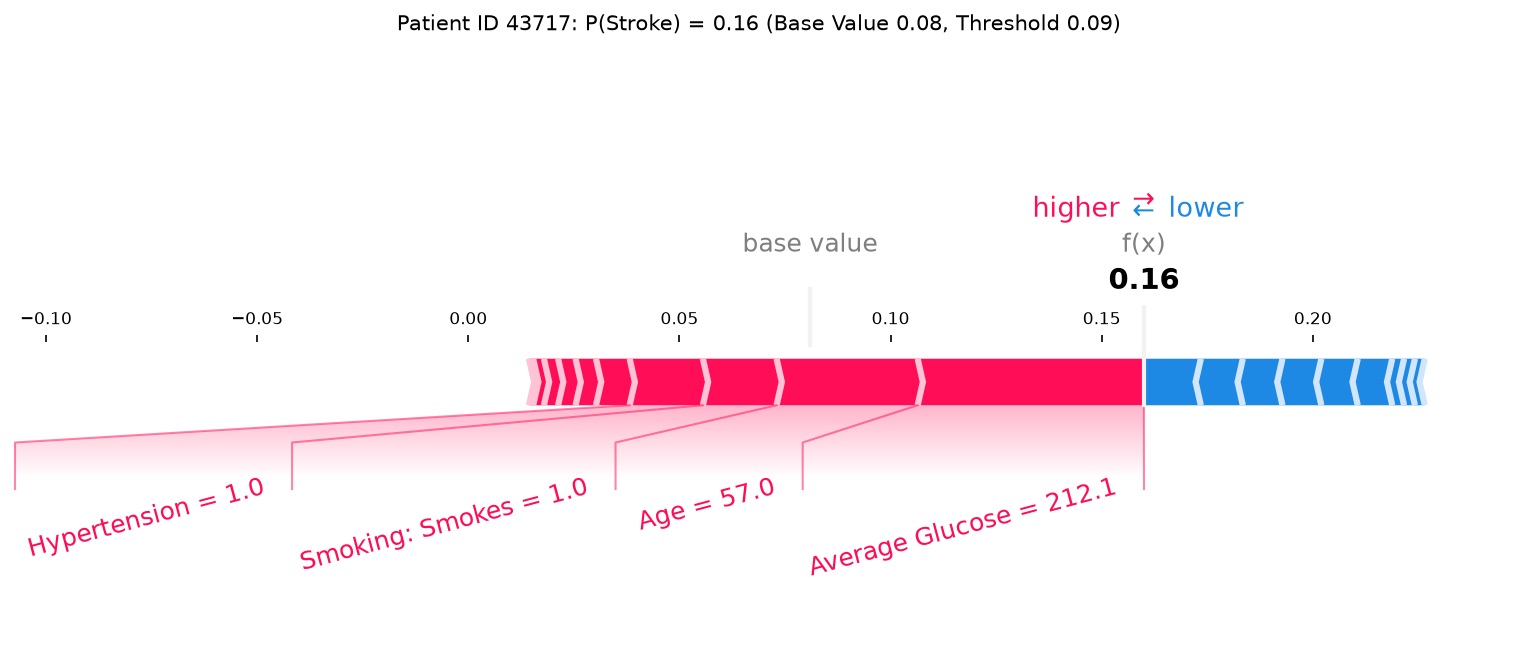

In [10]:
features = X_test.loc[case].set_axis(labels)
fig = force_plot(
    base_value,
    shap_values.loc[case].to_numpy(),
    features,
    f"Patient ID {case}: P(Stroke) = {proba[case]:.2f} "
    f"(Base Value {base_value:.2f}, Threshold {threshold:.2f})",
)
save_figure(fig, "shap_force_case")
plt.show()

### 5.2 Feature contributions

The three largest contributions; the last row combines the other 19 features, so the column adds up to the output minus the base value (0.16 − 0.08).

In [11]:
contributions = shap_values.loc[case].set_axis(labels)
top = contributions.abs().nlargest(3).index
table = pd.DataFrame({"Patient Value": features[top], "SHAP Value": contributions[top]})
table.loc["Remaining Features Combined"] = [np.nan, contributions.drop(top).sum()]
table.round(3)

,Patient Value,SHAP Value
Average Glucose,212.08,0.054
Age,57.00,0.033
Smoking: Smokes,1.00,0.017
Remaining Features Combined,NaN,-0.025


### 5.3 Interpretation

- **Flagged:** the score rises from the base value of 0.08 to 0.16, above the 0.09 threshold.
- **Upward:** average glucose of 212 mg/dL (+0.054, in the diabetic-range peak), age 57 (+0.033) and current smoking (+0.017); hypertension also pushes up (force plot).
- **Downward:** the remaining features combined (−0.025), each small on its own.
- **Plausibility:** all four are associated with stroke in the [EDA](01_eda.ipynb#sec-6-2) and are recognised clinical risk markers.
- **Limits:** 0.16 is a score, not a 16% risk ([Section 3.3](#sec-performance)); 21 of the 50 stroke patients fall below the threshold.

<a id="sec-global"></a>

## 6. Task 4: Global explanation

### 6.1 Beeswarm: direction

**Method:** one dot per patient and encoded feature, coloured by the feature's value (red = high or yes); the 12 features with the largest mean absolute SHAP value,

$$\overline{\lvert\phi_j\rvert} = \frac{1}{n}\sum_{i=1}^{n} \lvert\phi_{ij}\rvert,$$

where $\phi_{ij}$ is the SHAP value of feature $j$ for patient $i$. This is the only global plot that shows direction, so one-hot levels stay separate: a grouped variable such as Smoking has no single value to colour by.

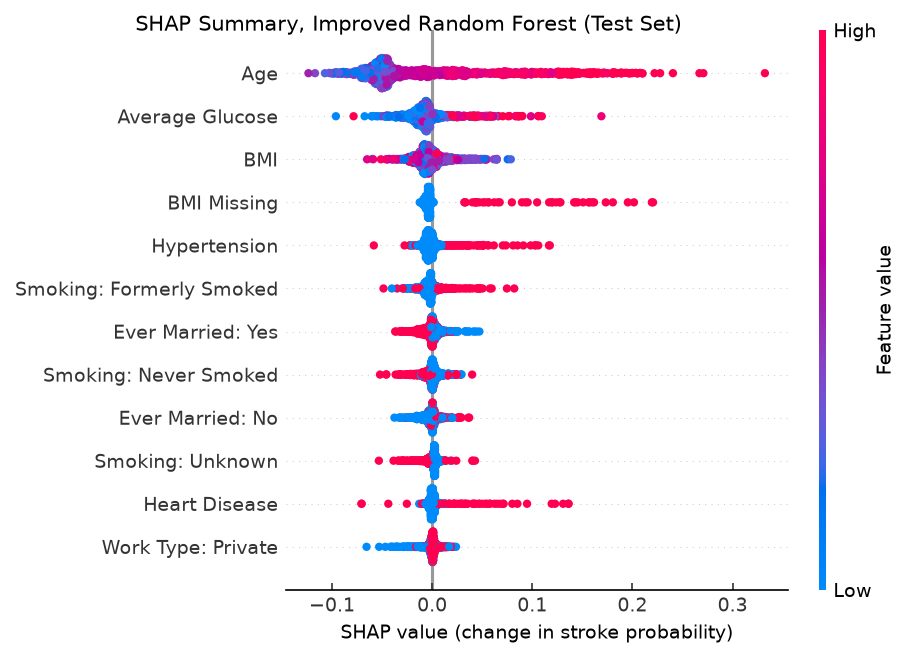

In [12]:
# SHAP calls tight_layout itself, which clashes with the theme's constrained layout
with plt.rc_context({"figure.constrained_layout.use": False}):
    shap.summary_plot(
        shap_values.to_numpy(),
        X_test,
        feature_names=list(labels),
        max_display=12,
        plot_size=(FIGURE_WIDTH, 4.5),
        show=False,
        rng=SEED,
    )
fig = plt.gcf()
for text in fig.findobj(Text):
    text.set_fontsize(9)
fig.axes[0].set_xlabel("SHAP value (change in stroke probability)")
fig.suptitle("SHAP Summary, Improved Random Forest (Test Set)")
save_figure(fig, "shap_beeswarm")
plt.show()

### 6.2 Importance by variable: ranking

**Method:** each patient's SHAP values are summed over a variable's one-hot levels, then averaged as $\overline{\lvert\phi_j\rvert}$ ([Section 6.1](#sec-global)), so each variable is ranked once. `BMI Missing` stays apart from `BMI`.

**Result:**
- **Age** dominates (0.060), about four times the next variable.
- **BMI fix:** BMI's importance falls and `BMI Missing` (0.008) appears; in the baseline the missingness signal was hidden inside BMI.
- **Hypertension and heart disease** rank low despite 3.3× and 4.0× crude stroke rates: few patients have them, and part of their effect is shared with age.
- **Ever married and work type** rank above hypertension as age proxies ([Section 7.3](#sec-dependence)).

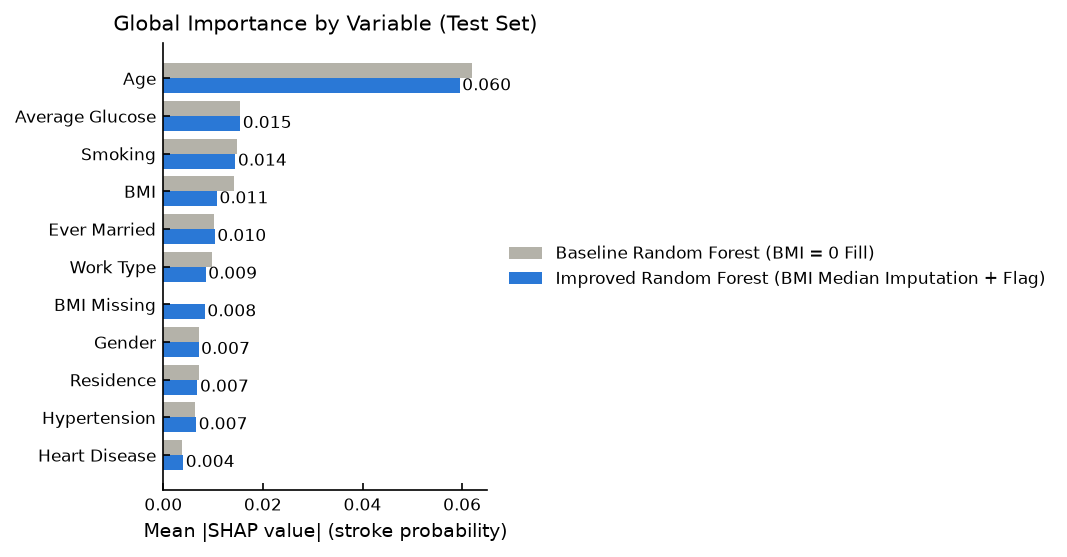

In [13]:
importance = pd.DataFrame(
    {
        "Baseline": importance_by_variable(shap_values_baseline),
        "Improved": importance_by_variable(shap_values),
    }
).sort_values("Improved")

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 3.6))
y = np.arange(len(importance))
ax.barh(
    y + 0.2,
    importance["Baseline"],
    height=0.4,
    color=COLORS["grey"],
    label="Baseline Random Forest (BMI = 0 Fill)",
)
ax.barh(
    y - 0.2, importance["Improved"], height=0.4, label="Improved Random Forest (BMI Median Imputation + Flag)"
)
for yi, value in zip(y, importance["Improved"], strict=True):
    ax.text(value + 0.0005, yi - 0.2, f"{value:.3f}", va="center", fontsize=8)
ax.set_yticks(y, importance.index)
ax.set(xlabel="Mean |SHAP value| (stroke probability)", title="Global Importance by Variable (Test Set)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
save_figure(fig, "shap_importance")
plt.show()

**Top five variables (improved random forest).** Directions from the beeswarm and the dependence plots.

| Rank | Variable | $\overline{\lvert\phi_j\rvert}$ | Pattern |
|---|---|---|---|
| 1 | Age | 0.060 | Pushes down below about 50, up above about 55, steeply after 60 |
| 2 | Average glucose | 0.015 | Upper peak (above about 170) mostly pushes up |
| 3 | Smoking | 0.014 | Formerly smoked mostly up; Unknown mostly down, as it marks young patients |
| 4 | BMI | 0.011 | Small; no consistent direction |
| 5 | Ever married | 0.010 | Small and mixed; acts as an age proxy |

### 6.3 Local case vs global pattern

- **Agreement:** the main case's (Patient ID 43717) two largest drivers, glucose and age, are the top two variables globally, acting in the typical direction.
- **Rare features matter locally:** hypertension ranks 10th globally (0.007) because only 10% of patients have it, yet it pushes this patient up.
- **Correlated predictors:** age, marital status and work type share one age signal, which SHAP splits between them (Aas et al., 2021); read them together.

<a id="sec-dependence"></a>

## 7. Feature effects

### 7.1 Dependence plots

**Method:** feature value (x) against its SHAP value (y), coloured by a second feature. If one colour sits consistently higher at the same x, the effect depends on the second feature (an interaction).

**Result:**
- **Age:** down below about 50, zero around 55, steeply up to 80. Hypertensive and other patients overlap at the same age: no visible interaction.
- **Average glucose:** the upper peak (above about 170) mostly pushes up; nearly all these patients are older.
- **BMI:** small effects; young patients near zero, larger values (both directions) in older patients.

**Implication:** age drives the model; glucose and BMI effects appear mainly in older patients. As older patients also have higher glucose, this is an observed pattern, not proof of an interaction.

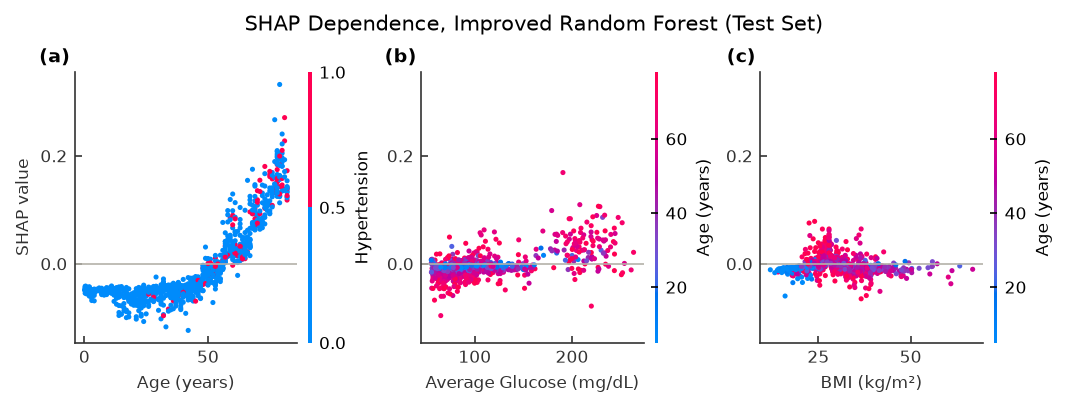

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, 2.6), sharey=True)
pairs = {"age": "hypertension", "avg_glucose_level": "age", "bmi": "age"}
for ax, (feature, colour) in zip(axes, pairs.items(), strict=True):
    shap.dependence_plot(
        feature, shap_values.to_numpy(), X_test, interaction_index=colour, ax=ax, show=False, dot_size=6
    )
    ax.axhline(0, color=COLORS["grey"], lw=0.8)
    ax.set_xlabel(axis_label(feature))
    ax.set_ylabel("SHAP value" if ax is axes[0] else "")
for colorbar, colour in zip(fig.axes[3:], pairs.values(), strict=True):
    colorbar.set_ylabel(axis_label(colour))
for text in fig.findobj(Text):
    text.set_fontsize(8)
label_panels(axes)
fig.suptitle("SHAP Dependence, Improved Random Forest (Test Set)")
save_figure(fig, "shap_dependence")
plt.show()

### 7.2 BMI under both pipelines

**Question:** does BMI = 0 get a large positive SHAP value in the baseline?

**Result:**
- **Baseline:** almost every patient with BMI = 0 is pushed up, by as much as +0.23, far above any recorded BMI: the model learned "BMI = 0 → stroke".
- **Improved:** the same patients sit at the median with small, still positive values (trees can recognise the exact imputed value); most of the signal moves to `BMI Missing`.

**Implication:** the model still uses missingness, a real association here (4.7× the stroke share: 19.9% vs 4.3%) that reflects data collection, not physiology. The fix makes it a named feature that can be audited or dropped.

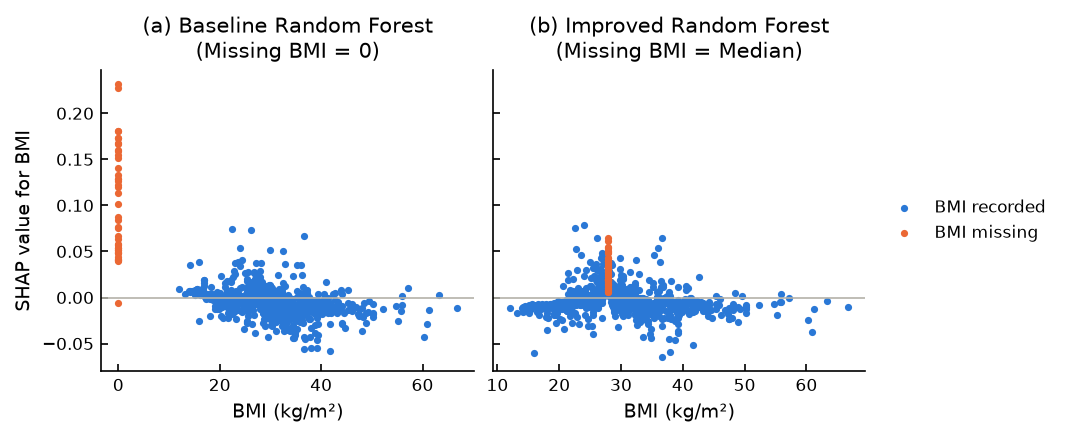

In [15]:
missing = X_test["bmi_missing"] == 1
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.8), sharey=True)
panels = [
    (axes[0], baseline.X_test, shap_values_baseline, "Baseline Random Forest\n(Missing BMI = 0)"),
    (axes[1], X_test, shap_values, "Improved Random Forest\n(Missing BMI = Median)"),
]
for ax, X, values, title in panels:
    ax.scatter(X.loc[~missing, "bmi"], values.loc[~missing, "bmi"], s=6, label="BMI recorded")
    ax.scatter(
        X.loc[missing, "bmi"], values.loc[missing, "bmi"], s=6, color=COLORS["orange"], label="BMI missing"
    )
    ax.axhline(0, color=COLORS["grey"], lw=0.8)
    ax.set(xlabel=axis_label("bmi"), title=title)
axes[0].set_ylabel("SHAP value for BMI")
label_panels(axes)
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
save_figure(fig, "shap_bmi_artefact")
plt.show()

**Same patient, both models** (the missing-BMI stroke patient the baseline scores highest): "BMI = 0" is the second-largest upward push in the baseline; in the improved random forest `BMI Missing` takes its place and the imputed median adds a smaller push.

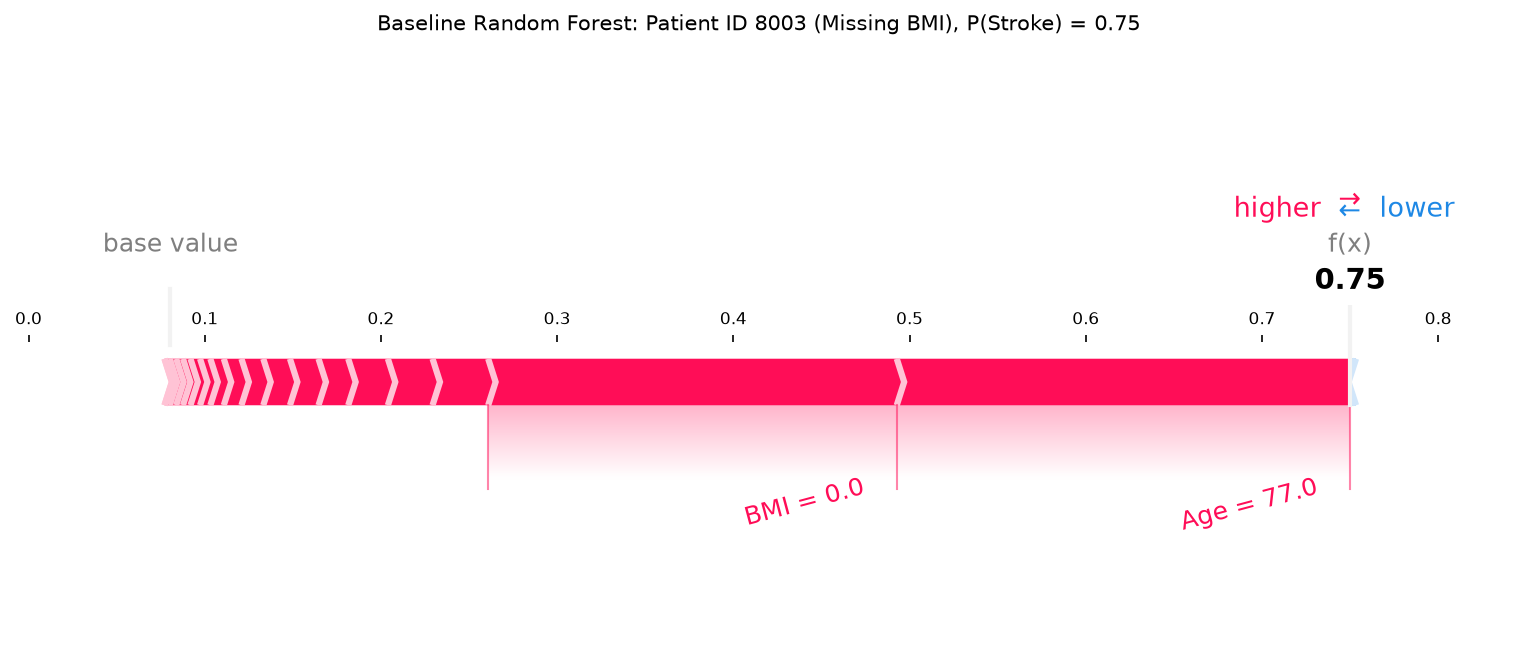

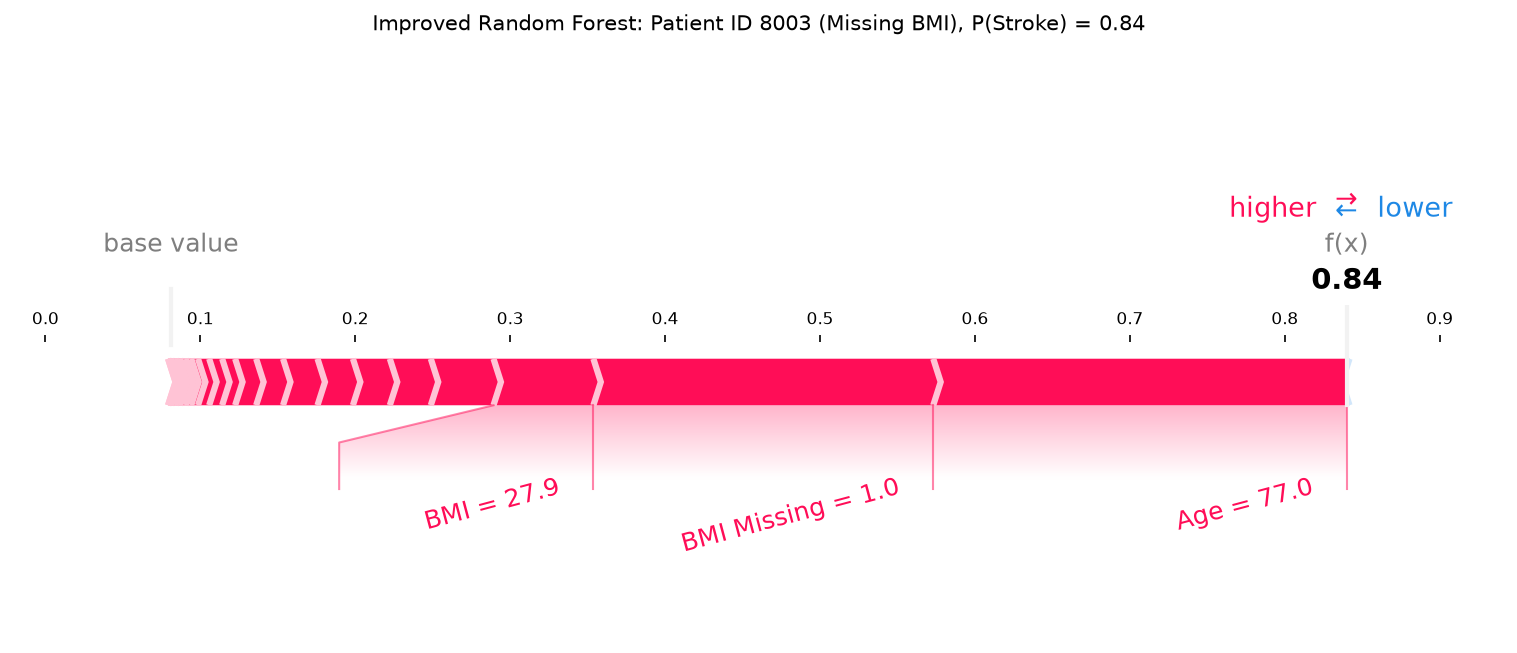

In [16]:
bmi_case = proba_baseline[missing & (y_test == 1)].idxmax()
models = [
    ("Baseline Random Forest", baseline.X_test, shap_values_baseline, base_value_baseline, proba_baseline),
    ("Improved Random Forest", X_test, shap_values, base_value, proba),
]
for name, X, values, base, p in models:
    fig = force_plot(
        base,
        values.loc[bmi_case].to_numpy(),
        X.loc[bmi_case].set_axis(X.columns.map(display_label)),
        f"{name}: Patient ID {bmi_case} (Missing BMI), P(Stroke) = {p[bmi_case]:.2f}",
    )
    save_figure(fig, f"shap_force_bmi_{name.split()[0].lower()}")
    plt.show()

### 7.3 Marital status and age

**Question:** is the `Ever Married` attribution a proxy for age ($\rho = 0.66$, [EDA, Section 7.4](01_eda.ipynb#sec-7-4))?

**Reading:** an effect of its own would separate the two groups at every age; a proxy shows values ordered by age instead.

**Result:** a proxy pattern. Young patients (blue) sit near zero in both groups; large values belong to older patients (red), mostly up for the unmarried and slightly down for the married.

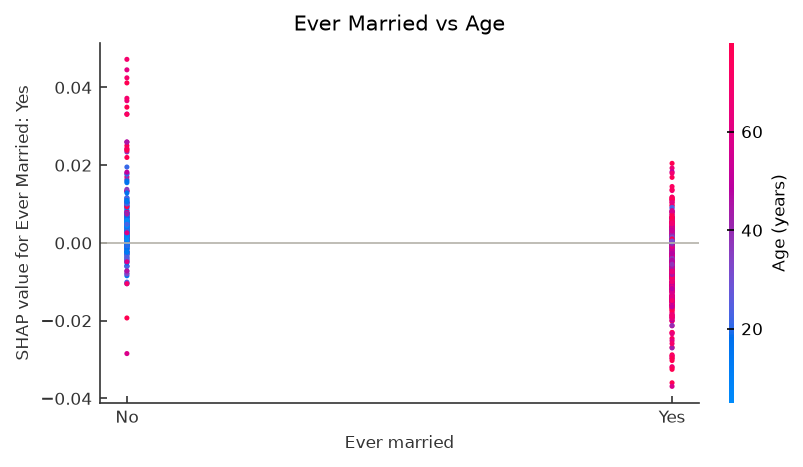

In [17]:
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 3))
shap.dependence_plot(
    "ever_married_Yes", shap_values.to_numpy(), X_test, interaction_index="age", ax=ax, show=False, dot_size=6
)
ax.axhline(0, color=COLORS["grey"], lw=0.8)
ax.set(xlabel="Ever married", ylabel="SHAP value for Ever Married: Yes", title="Ever Married vs Age")
ax.set_xticks([0, 1], ["No", "Yes"])
fig.axes[-1].set_ylabel(axis_label("age"))
for text in fig.findobj(Text):
    text.set_fontsize(8)
ax.title.set_fontsize(10)
save_figure(fig, "shap_ever_married")
plt.show()

<a id="sec-robustness"></a>

## 8. Robustness checks

### 8.1 Explanation stability

**Question:** do the conclusions depend on the reference the SHAP values are measured from?

**Method:**
- **Two more backgrounds** of 100 training patients (`random_state=2022` and `random_state=2023`). SHAP itself subsamples any background above 100 patients, so a larger one is not used.
- **Tree path-dependent** (the provided default): no background; an unknown feature follows both branches of each split, weighted by the training rows that went each way. Its reference is the oversampled training set (50% strokes).

**Result:**
- **Interventional:** base value 0.06–0.09, the same five variables lead, and the top three contributions of the main case (Patient ID 43717) keep their signs.
- **Path-dependent:** same five variables, but base value 0.50. The main case (Patient ID 43717, scored 0.16 by the random forest) now sits below the reference, so its contributions turn negative: the question becomes "why lower than a typical oversampled row?".

**Implication:** the ranking is robust; the sign of a contribution depends on the reference, so the reference is stated with every plot.

In [18]:
backgrounds = {
    "Interventional, random_state=2021 (main)": background,
    "Interventional, random_state=2022": X_train.sample(BACKGROUND_SIZE, random_state=2022),
    "Interventional, random_state=2023": X_train.sample(BACKGROUND_SIZE, random_state=2023),
    "Tree path-dependent": None,
}
top_columns = shap_values.loc[case].abs().nlargest(3).index

stability = {}
for name, reference in backgrounds.items():
    values, base = tree_shap(rf, X_test, reference)
    signs = ["+" if float(values.loc[case, column]) > 0 else "−" for column in top_columns]
    stability[name] = {
        "Base Value": round(base, 3),
        "Top 5 Variables": ", ".join(importance_by_variable(values).index[:5]),
        "Main Case, Top-3 Signs": ", ".join(
            f"{display_label(c)} ({s})" for c, s in zip(top_columns, signs, strict=True)
        ),
        "Max Residual": f"{additivity_residual(base, values, proba).max():.1e}",
    }
pd.DataFrame.from_dict(stability, orient="index")

 96%|=================== | 1963/2044 [00:25<00:01]       

,Base Value,Top 5 Variables,"Main Case, Top-3 Signs",Max Residual
"Interventional, random_state=2021 (main)",0.081,"Age, Average Glucose, Smoking, BMI, Ever Married","Average Glucose (+), Age (+), Smoking: Smokes (+)",3.0e-02
"Interventional, random_state=2022",0.061,"Age, Average Glucose, Smoking, Ever Married, BMI","Average Glucose (+), Age (+), Smoking: Smokes (+)",3.0e-02
"Interventional, random_state=2023",0.090,"Age, Average Glucose, Smoking, BMI, Ever Married","Average Glucose (+), Age (+), Smoking: Smokes (+)",3.0e-02
Tree path-dependent,0.501,"Age, Average Glucose, BMI, Smoking, Ever Married","Average Glucose (−), Age (−), Smoking: Smokes (−)",3.6e-15


### 8.2 Subgroup performance

**Question:** does the tuned model catch strokes equally well across sex and age? Two age bands only, as there are few strokes under 60.

**Result:**
- **Sex:** recall 0.53 for women and 0.65 for men, with similar false positive rates; with 30 and 20 strokes, this gap is within chance.
- **Age:** recall 0.79 at 60 and over but 0.32 under 60, while 0.66 of older non-stroke patients are flagged. The model works mainly as an age filter.

In [19]:
subgroups = {
    "Female": X_test["gender_Female"] == 1,
    "Male": X_test["gender_Male"] == 1,
    "Age < 60": X_test["age"] < 60,
    "Age ≥ 60": X_test["age"] >= 60,
}
rows = {}
for name, mask in subgroups.items():
    metrics = evaluate(y_test[mask], proba[mask], threshold)
    false_positive_rate = metrics["False Alarms (FP)"] / (
        metrics["False Alarms (FP)"] + metrics["Correctly Cleared (TN)"]
    )
    rows[name] = {
        "Patients": mask.sum(),
        "Strokes": y_test[mask].sum(),
        "Recall": metrics["Recall"],
        "False Positive Rate": false_positive_rate,
    }
pd.DataFrame.from_dict(rows, orient="index").round(3)

,Patients,Strokes,Recall,False Positive Rate
Female,604,30,0.533,0.225
Male,418,20,0.650,0.241
Age < 60,734,22,0.318,0.074
Age ≥ 60,288,28,0.786,0.662


<a id="sec-supplementary"></a>

## 9. Supplementary cases

One patient from each other cell of the confusion matrix: the stroke patient with the lowest score (false negative), and the median-scoring non-stroke patient among those flagged (false positive) and those cleared (true negative).

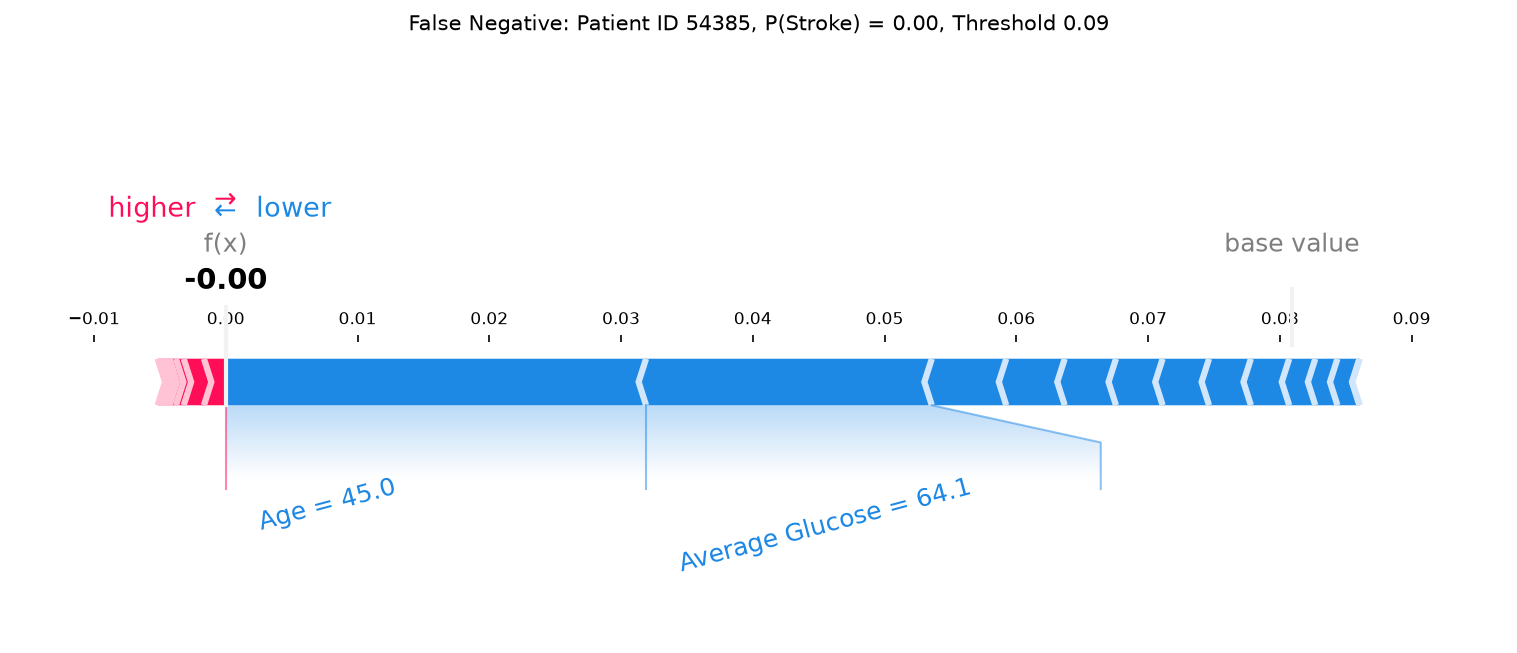

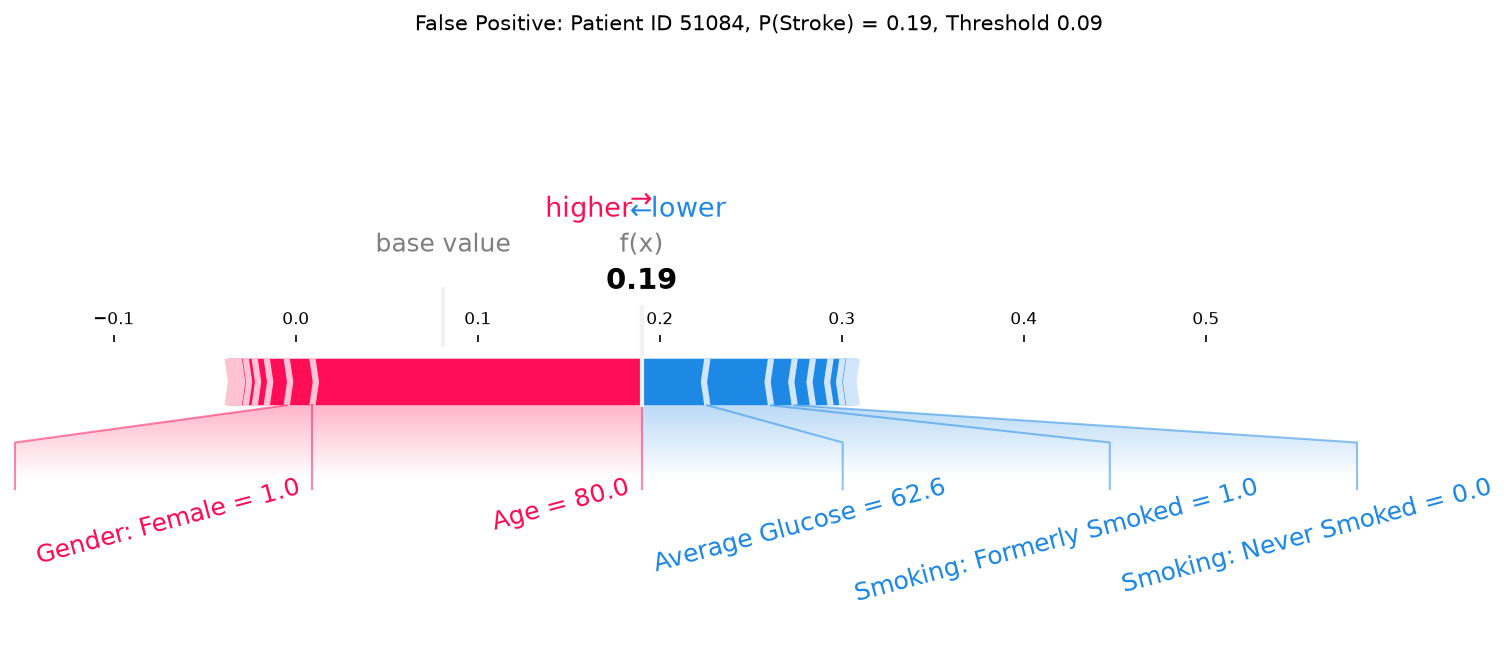

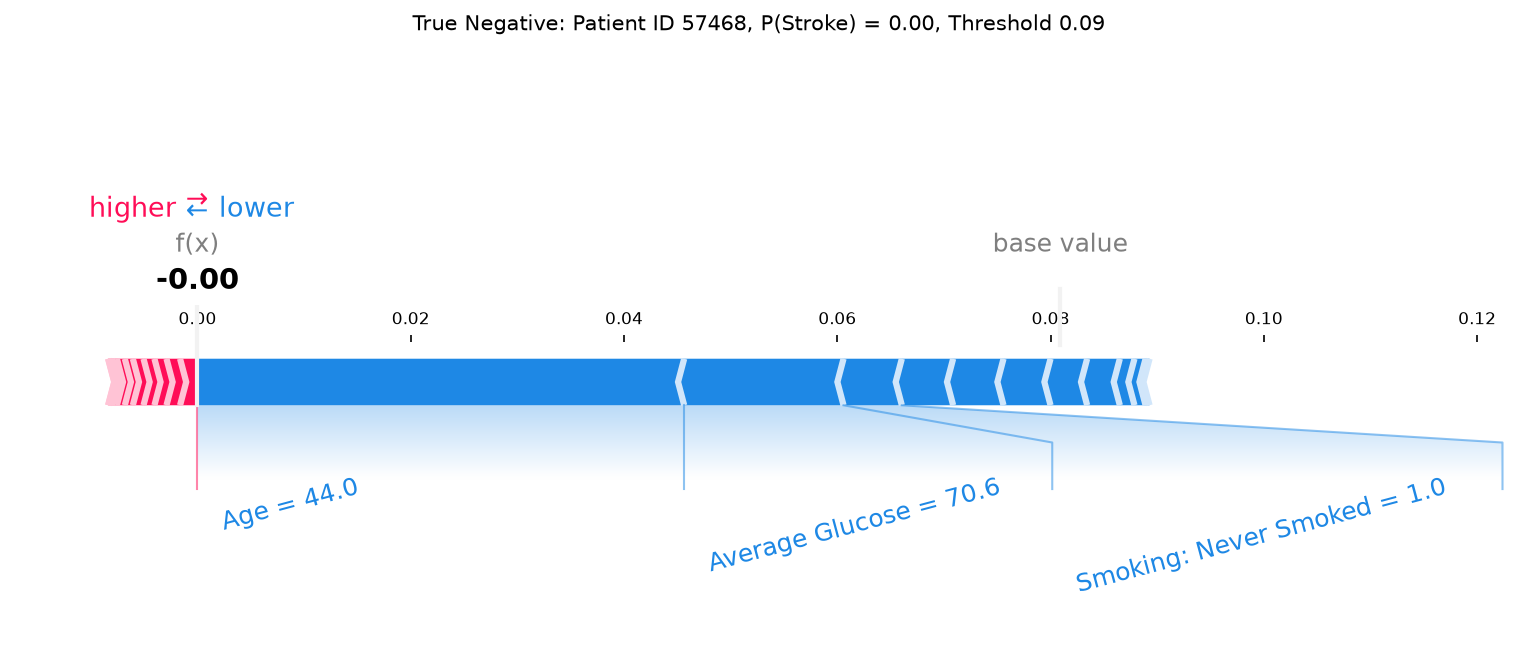

In [20]:
no_stroke = proba[y_test == 0].sort_values(kind="stable")
false_positives, true_negatives = no_stroke[no_stroke >= threshold], no_stroke[no_stroke < threshold]
supplementary = {
    "False Negative": proba[y_test == 1].idxmin(),
    "False Positive": false_positives.index[(len(false_positives) - 1) // 2],
    "True Negative": true_negatives.index[(len(true_negatives) - 1) // 2],
}
for name, patient_id in supplementary.items():
    fig = force_plot(
        base_value,
        shap_values.loc[patient_id].to_numpy(),
        X_test.loc[patient_id].set_axis(labels),
        f"{name}: Patient ID {patient_id}, P(Stroke) = {proba[patient_id]:.2f}, Threshold {threshold:.2f}",
    )
    save_figure(fig, f"shap_force_{name.lower().replace(' ', '_')}")
    plt.show()

<a id="sec-takeaways"></a>

## 10. Key takeaways

1. **Accuracy hides failure** ([Section 3](#sec-performance)): 94% accurate, but only 4 of 50 strokes caught. The tuned threshold (0.09) catches 29, at the cost of 225 false alarms.
2. **The BMI artefact is confirmed** ([Section 7.2](#sec-dependence)): the baseline uses "BMI = 0" as a stroke signal. Median imputation plus a flag moves it into a visible `BMI Missing` feature and raises ROC AUC from 0.73 to 0.75.
3. **Age dominates** ([Section 6](#sec-global)): about four times the next variable; marital status and work type act partly as age proxies.
4. **The local case is plausible** ([Section 5](#sec-local)): high glucose, age, smoking and hypertension lift the main case (Patient ID 43717) from 0.08 to 0.16.
5. **Rankings are stable; signs depend on the reference** ([Section 8.1](#sec-robustness)).
6. **Younger stroke patients are mostly missed** ([Section 8.2](#sec-robustness)): recall 0.32 under 60 vs 0.79 at 60 and over.

<a id="sec-references"></a>

## 11. References

Aas, K., Jullum, M., & Løland, A. (2021). Explaining individual predictions when features are dependent: More accurate approximations to Shapley values. *Artificial Intelligence, 298*, 103502. https://doi.org/10.1016/j.artint.2021.103502

deepfindr. (2021). *xai-series* [Computer software]. GitHub. https://github.com/deepfindr/xai-series

Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774.

Youden, W. J. (1950). Index for rating diagnostic tests. *Cancer, 3*(1), 32–35. https://doi.org/10.1002/1097-0142(1950)3:1<32::AID-CNCR2820030106>3.0.CO;2-3